# Modul 02: In-Depth Exploratory Data Analysis & Advanced Feature Engineering Pipeline
### Mata Kuliah: Data Mining — Program Studi Teknik Informatika
**Dosen Pengampu:** Abu Salam, M.Kom  
**Penyusun:** Nayyara Rauf Ghani Al Khayri (NIM: A11.2024.16055)  
**Lingkungan Eksekusi:** Local Python 3.13 Virtual Environment (`.venv`) + SQLite Database  

---

## 1. Executive Summary & Problem Framing

### 1.1 Konteks Analitis & Rekayasa Fitur
Setelah data mentah dibersihkan dan diimputasi pada **Modul 01**, tahap krusial berikutnya dalam metodologi penambangan data (*data mining methodology*) adalah mentransformasikan atribut-atribut mentah menjadi representasi fitur (*feature representations*) yang optimal bagi algoritma pembelajaran mesin (*machine learning*). Model prediktif parametrik (seperti Regresi Logistik) mengasumsikan varians homogen dan linearitas independen, sedangkan model non-linear berbasis *tree ensembles* (seperti Random Forest dan XGBoost) sangat diuntungkan oleh fitur turunan domain (*business features*) yang mengekspresikan interaksi antar-variabel secara eksplisit.

Tujuan teknis utama dari **Modul 02** dirumuskan ke dalam 6 pilar:
1. **Exploratory Data Analysis (EDA) Terarah**:
   - Mengkuantifikasi distribusi target `Churn`, menghitung rasio ketimpangan kelas (*class imbalance ratio*), dan merumuskan strategi penanganan imbalance (pembobotan loss, teknik resampling SMOTE, serta pemilihan metrik evaluasi PR-AUC/Cost-Sensitive).
   - Melakukan analisis bivariat numerik (KDE, Boxplot, dan violin plot) dan kategorikal (churn rate breakdown per segmen layanan) menggunakan visualisasi Seaborn/Matplotlib yang standar publikasi.
2. **Feature Transformation (Automated Skewness Remediation)**:
   - Mendeteksi koefisien kemiringan (*skewness*) secara otomatis pada seluruh fitur kontinu (`tenure`, `MonthlyCharges`, `TotalCharges`).
   - Membandingkan secara empiris efektivitas **PowerTransformer (Yeo-Johnson)** terhadap **Log1p Transformation** dalam menormalkan distribusi data.
3. **Structured Categorical Encoding**:
   - Menerapkan **Binary Encoding** (0/1) untuk fitur biner murni (`gender`, `Partner`, `Dependents`, `PhoneService`, `PaperlessBilling`).
   - Menerapkan **Ordinal Encoding** untuk fitur bertingkat hierarkis (`Contract`).
   - Menerapkan **One-Hot Encoding dengan `drop='first'`** pada fitur nominal multi-kelas guna memproteksi matriks kovariansi dari jebakan multikolinearitas (*dummy variable trap*).
4. **Feature Engineering Mandiri (Domain-Specific Business Features)**:
   - Menciptakan 5 fitur turunan berbasis pengetahuan domain telekomunikasi: `Tenure_Group` (kohort loyalitas), `Average_Monthly_Charges`, `Ratio_Total_to_Monthly_Charge`, `Flag_High_Risk_Contract`, dan `Num_Support_Services`.
5. **Multicollinearity Diagnostics & Feature Selection**:
   - Menguji *Variance Inflation Factor* (VIF) untuk mendeteksi redundansi aljabar dan mengeliminasi fitur collinear secara terarah.
   - Memeringkat kepentingan fitur menggunakan perpaduan **Mutual Information Score** ($I(X; Y)$) dan **Random Forest Gini Importance**.
6. **Persistence & Feature Store**:
   - Menyimpan dataset siap latih ke `data/processed/telco_churn_featured.csv`, `data/processed/telco_featured.csv`, serta tabel SQLite `featured_customers`.


## 2. Pipeline Architecture & Workflow

Diagram alir terpadu Modul 02 dirancang secara deterministik dan terlacak (*traceable*):

```
+-------------------------------------------------------------------------------------------------+
|                         MODUL 02: IN-DEPTH EDA & ADVANCED FEATURE ENGINEERING                   |
+-------------------------------------------------------------------------------------------------+
                                                 |
                                                 v
                      [Input Source: SQLite cleaned_customers / telco_cleaned.csv]
                                                 |
         +───────────────────────────────────────┴───────────────────────────────────────+
         |                                                                               |
         v                                                                               v
[1. Target Distribution & Imbalance]                            [2. Bivariate EDA Analysis]
 - Count & Percentage Breakdown (657 No vs 543 Yes)              - Numeric vs Churn (KDE & Boxplots)
 - Imbalance Ratio (1.21 : 1) & Strategy Framing                 - Categorical Churn Breakdown (%)
 - Donut Chart & Dual Countplot                                  - Pearson Correlation Heatmap
         |                                                                               |
         +───────────────────────────────────────┬───────────────────────────────────────+
                                                 |
                                                 v
                              [3. Feature Transformation Analysis]
                               - Automated Skewness Detection (|skew| > 0.5)
                               - Yeo-Johnson PowerTransformer vs Log1p
                               - 3-Panel Distribution Visual Comparison
                                                 |
                                                 v
                              [4. Domain Feature Engineering Mandiri]
                               - Tenure_Group (Cohort 0-3)
                               - Average_Monthly_Charges & Ratio
                               - Flag_High_Risk_Contract & Num_Support_Services
                                                 |
                                                 v
                              [5. Structured Categorical Encoding]
                               - Binary Encoding (gender, Partner, Dependents, Phone, Billing)
                               - Ordinal Encoding (Contract: 0 < 1 < 2)
                               - One-Hot Encoding nominals with drop='first' (No Dummy Trap)
                                                 |
                                                 v
                              [6. Multicollinearity Diagnostics (VIF)]
                               - Initial VIF Calculation (Highlighting Inf & Collinearities)
                               - Targeted Elimination (Drop Raw TotalCharges, Ratio, Avg Charges)
                               - Post-Elimination VIF Verification (All Safe)
                                                 |
                                                 v
                              [7. Information-Theoretic Feature Selection]
                               - Non-linear Mutual Information Score (I(X; Y))
                               - Random Forest Gini Importance (Mean Decrease Impurity)
                               - Composite Normalized Importance Ranking
                                                 |
                                                 v
                              [8. Output Export & Verification]
                               - data/processed/telco_churn_featured.csv
                               - data/processed/telco_featured.csv
                               - SQLite: featured_customers Table
```


In [1]:
# 1. Setup Lingkungan Komputasi & Import Dependensi
import sys
from pathlib import Path

ROOT_DIR = Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import PowerTransformer
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from statsmodels.stats.outliers_influence import variance_inflation_factor

from src.config import (
    DB_PATH, CLEANED_TABLE, FEATURED_TABLE, NUMERIC_COLUMNS,
    NOMINAL_COLUMNS, ORDINAL_COLUMNS, TARGET_COLUMN,
    RANDOM_STATE, PROCESSED_DATA_DIR
)
from src.logger import get_logger
from src.database import read_from_sqlite, save_to_sqlite
from src.eda import (
    calculate_distribution_metrics, plot_target_distribution,
    plot_feature_distributions, plot_bivariate_continuous_boxplots,
    plot_categorical_churn_breakdown, plot_correlation_matrix
)
from src.feature_engineering import (
    compare_skewness_remediations, auto_skewness_transform,
    create_business_features, encode_categorical_features,
    calculate_vif, compute_feature_importance_ranking,
    run_complete_feature_engineering_pipeline
)

# Styling konfigurasi visualisasi
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "font.family": "sans-serif",
    "figure.dpi": 120,
    "axes.titlesize": 11,
    "axes.labelsize": 10
})

logger = get_logger("Notebook_02")
logger.info("Modul 02: Environment komputasi siap digunakan.")
print("Semua dependensi dan pustaka analitis berhasil diimpor.")


2026-10-24 23:47:30 | INFO     | Notebook_02:<module>:49 - Modul 02: Environment komputasi siap digunakan.


Semua dependensi dan pustaka analitis berhasil diimpor.


---

## 3. Ekstraksi Data Bersih dari SQLite Golden Store

Kita mengekstraksi dataset pelanggan yang telah melalui proses validasi skema, deduplikasi, imputasi MICE, dan audit pencilan multidimensi pada **Modul 01** dari tabel `cleaned_customers` pada database operasional `data/telco_churn.db`.


In [2]:
# Membaca data bersih dari SQLite database
df_clean = read_from_sqlite(CLEANED_TABLE, db_path=DB_PATH)

print("=== RINGKASAN DATASET BERSIH DARI SQLITE (cleaned_customers) ===")
print(f"Total Observasi : {df_clean.shape[0]:,} baris")
print(f"Total Kolom     : {df_clean.shape[1]} atribut")
print(f"Missing Values  : {df_clean.isnull().sum().sum()} nilai kosong")
print(f"Daftar Kolom    : {df_clean.columns.tolist()}\n")

display(df_clean.head(5))


2026-10-24 23:47:30 | INFO     | DatabaseManager:read_from_sqlite:133 - Executing SQLite query: SELECT * FROM cleaned_customers...


2026-10-24 23:47:30 | INFO     | DatabaseManager:read_from_sqlite:136 - Query returned 1200 rows and 18 columns.


=== RINGKASAN DATASET BERSIH DARI SQLITE (cleaned_customers) ===
Total Observasi : 1,200 baris
Total Kolom     : 18 atribut
Missing Values  : 0 nilai kosong
Daftar Kolom    : ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'TechSupport', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'anomaly_score']



,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,TechSupport,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,anomaly_score
0,1001-ABCD,Male,0,No,No,43.0,Yes,No,Fiber optic,No,No internet service,Month-to-month,No,Credit card (automatic),75.01,3228.52,Yes,0.141894
1,1002-ABCD,Female,0,No,No,72.0,Yes,No,Fiber optic,No internet service,No internet service,Month-to-month,No,Electronic check,59.50,4287.89,Yes,0.033989
2,1003-ABCD,Male,0,Yes,Yes,72.0,Yes,No,Fiber optic,Yes,No internet service,Month-to-month,No,Mailed check,65.23,4688.51,Yes,0.040120
3,1004-ABCD,Male,0,Yes,No,42.0,Yes,No,No,No,No,One year,Yes,Bank transfer (automatic),27.69,1164.42,No,0.065191
4,1005-ABCD,Male,0,Yes,No,26.0,Yes,No phone service,Fiber optic,Yes,No,Month-to-month,Yes,Bank transfer (automatic),65.92,1704.52,Yes,0.167545


---

## 4. Exploratory Data Analysis (EDA) Terarah

### 4.1 Distribusi Target (Churn) & Analisis Class Imbalance Ratio
Dalam perancangan sistem analitik prediktif bisnis, pemahaman mendalam terhadap proporsi kelas target merupakan langkah awal yang krusial. Pada kasus retensi pelanggan telekomunikasi, ketidakseimbangan kelas (*class imbalance*) sering kali menjadi tantangan utama:
- **Accuracy Paradox**: Model yang selalu memprediksi kelas mayoritas (*Non-Churn*) dapat mencatat akurasi tampak tinggi, namun gagal mendeteksi pelanggan yang benar-benar berisiko berhenti berlangganan (*False Negative*).
- **Rasio Ketimpangan (*Imbalance Ratio*)**:
  $$\text{Imbalance Ratio} = \frac{N(\text{Mayoritas})}{N(\text{Minoritas})}$$
  Pada dataset terkurasi ini ($N = 1.200$), mari kita periksa proporsi kelas empiris dan strategi mitigasi pemodelannya.


=== METRIK KUANTITATIF DISTRIBUSI KELAS TARGET (CHURN) ===


,Kategori_Target,Jumlah_Pelanggan,Persentase (%)
0,No,657,54.75
1,Yes,543,45.25


Rasio Ketimpangan Kelas (Imbalance Ratio): 1.21 : 1


C:\Users\Admin\Documents\Data Mining Course\src\eda.py:91: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=target_col, palette=palette, ax=ax1, edgecolor="black", linewidth=1.2)


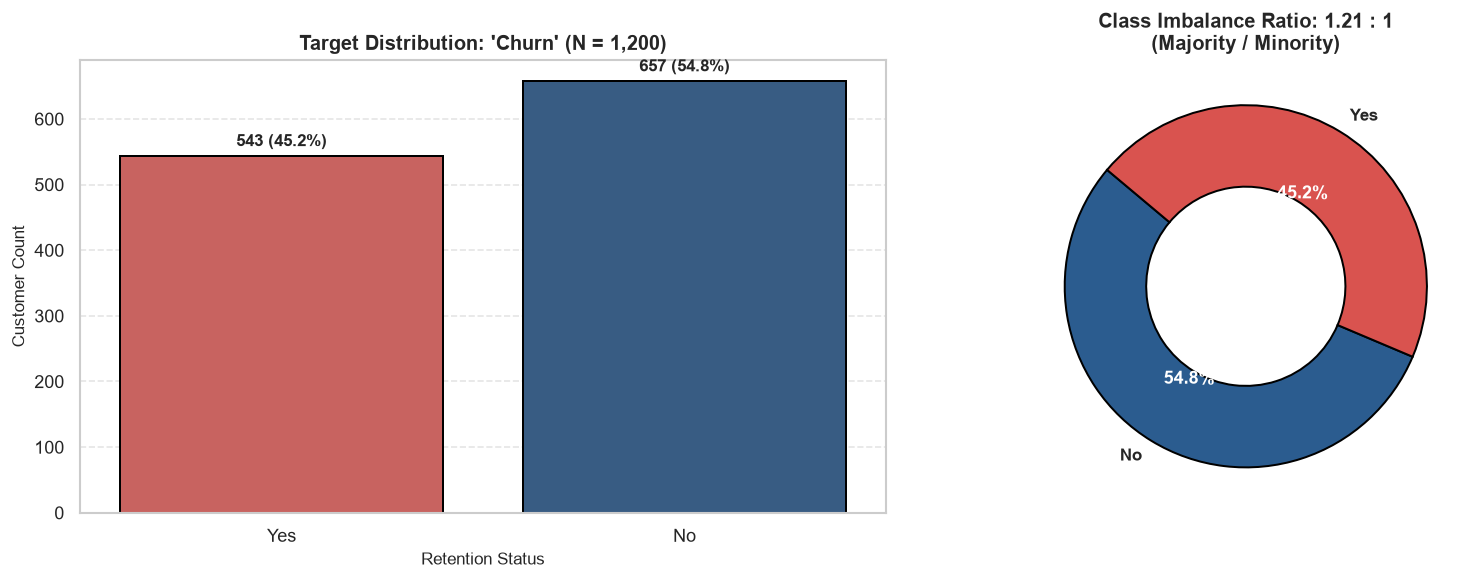

In [3]:
# Perhitungan Kuantitatif Distribusi Target Churn
churn_counts = df_clean["Churn"].value_counts()
churn_props = df_clean["Churn"].value_counts(normalize=True) * 100
imbalance_ratio = churn_counts["No"] / churn_counts["Yes"]

target_summary_df = pd.DataFrame({
    "Kategori_Target": churn_counts.index,
    "Jumlah_Pelanggan": churn_counts.values,
    "Persentase (%)": churn_props.values.round(2)
})

print("=== METRIK KUANTITATIF DISTRIBUSI KELAS TARGET (CHURN) ===")
display(target_summary_df)
print(f"Rasio Ketimpangan Kelas (Imbalance Ratio): {imbalance_ratio:.2f} : 1")

# Visualisasi Distribusi Target Terpadu (Dual Plot: Countplot + Donut Chart)
fig_target = plot_target_distribution(df_clean, target_col="Churn")
plt.show()


### 💡 Interpretasi Analitik & Strategi Mitigasi Class Imbalance
> [!NOTE]
> 1. **Karakteristik Distribusi**:
>    - Kelas mayoritas (`No` / Aktif): **657 pelanggan (54.75%)**
>    - Kelas minoritas (`Yes` / Churn): **543 pelanggan (45.25%)**
>    - Rasio ketimpangan tercatat **1.21 : 1**, menunjukkan distribusi yang relatif seimbang pada sampel ini dibandingkan populasi industri telekomunikasi umum (~73% vs 27%, rasio ~2.76 : 1).
> 2. **Formulasi Strategi Mitigasi untuk Tahap Pemodelan (Modul 03)**:
>    - **Algorithmic Weighting**: Menerapkan parameter `class_weight='balanced'` pada fungsi kerugian (*loss function*) Logistic Regression dan Random Forest guna memberikan penalti proporsional terhadap *False Negative*.
>    - **Resampling Strategy**: Menggunakan SMOTE (*Synthetic Minority Over-sampling Technique*) apabila dilakukan evaluasi terhadap sensitivitas batas keputusan (*decision boundary*).
>    - **Evaluasi Non-Akurasi**: Memprioritaskan metrik **PR-AUC (*Precision-Recall Area Under Curve*)**, **ROC-AUC**, dan **Cost-Sensitive Expected Value Loss** daripada akurasi mentah (*accuracy*).


### 4.2 Analisis Bivariat Fitur Numerik Kontinu terhadap Churn
Kita menganalisis pemisahan distribusi (*distribution separation*) pada variabel kontinu utama: `tenure` (lama berlangganan dalam bulan), `MonthlyCharges` (tagihan bulanan dalam USD), dan `TotalCharges` (akumulasi pengeluaran pelanggan) terhadap status `Churn`.


=== STATISTIK DESKRIPTIF FITUR KONTINU TERHADAP CHURN ===


Churn                           No          Yes
tenure         mean      37.869102    34.788214
               median    40.000000    33.000000
               std       19.780994    21.476953
MonthlyCharges mean      58.851522    67.914438
               median    60.360000    72.430000
               std       19.129668    18.717944
TotalCharges   mean    2250.519925  2369.375531
               median  1990.530000  2113.710000
               std     1467.325484  1645.055129

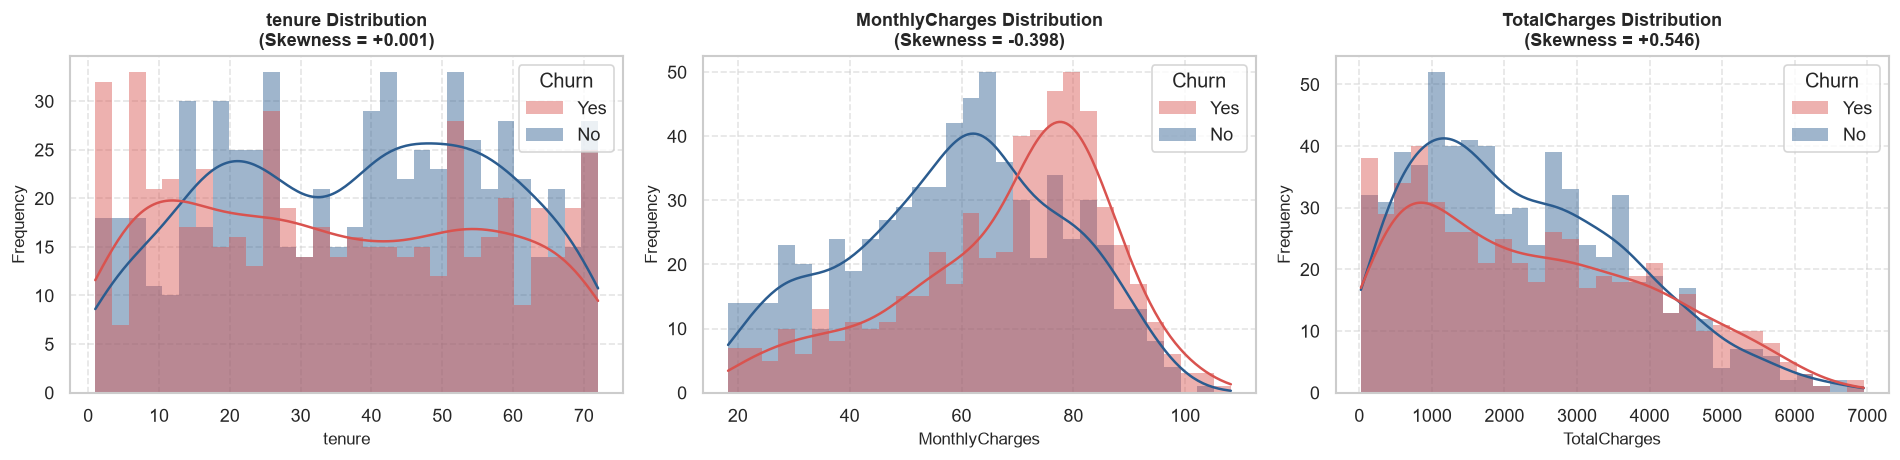

C:\Users\Admin\Documents\Data Mining Course\src\eda.py:187: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Admin\Documents\Data Mining Course\src\eda.py:187: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Admin\Documents\Data Mining Course\src\eda.py:187: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


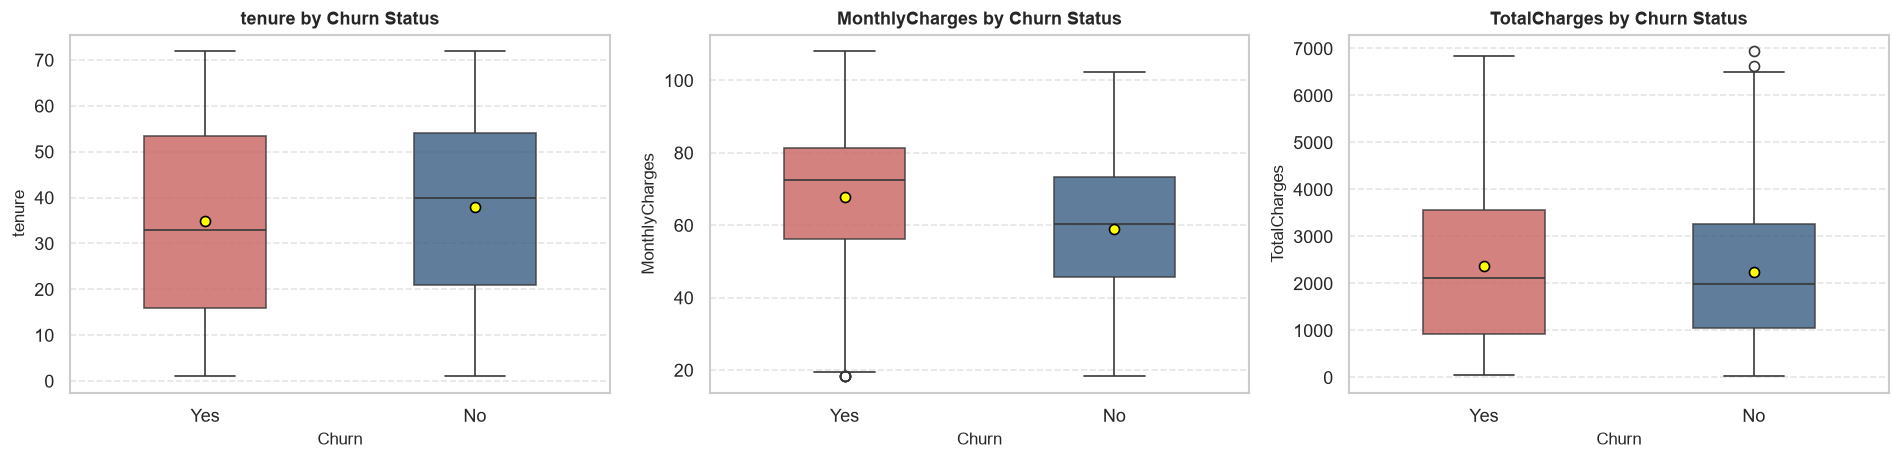

In [4]:
# 1. Ringkasan Statistik Deskriptif Terstratifikasi Status Churn
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
bivariate_stats = df_clean.groupby("Churn")[numeric_cols].agg(["mean", "median", "std"]).T
print("=== STATISTIK DESKRIPTIF FITUR KONTINU TERHADAP CHURN ===")
display(bivariate_stats)

# 2. Visualisasi Histogram & Overlaid KDE Terstratifikasi Churn
fig_num_dist = plot_feature_distributions(df_clean, numeric_cols=numeric_cols, target_col="Churn")
plt.show()

# 3. Visualisasi Boxplot & Deteksi Pemisahan Kuartil (Yellow Dot = Mean)
fig_box = plot_bivariate_continuous_boxplots(df_clean, numeric_cols=numeric_cols, target_col="Churn")
plt.show()


### 4.3 Analisis Bivariat Fitur Kategorikal Strategis terhadap Churn
Kita menelaah tingkat retensi pada segmen kontraktual, jenis koneksi internet, dukungan teknis, dan metode pembayaran.


=== TINGKAT CHURN RATE (%) PADA BERBAGAI SEGMEN LAYANAN ===


,Category_Value,Churn_Rate_Pct,Feature
4,Fiber optic,59.772296,InternetService
0,Month-to-month,59.759760,Contract
7,No internet service,48.175182,TechSupport
11,Electronic check,47.972973,PaymentMethod
14,No internet service,47.773279,OnlineSecurity
10,Credit card (automatic),47.272727,PaymentMethod
6,No,47.254576,TechSupport
12,Mailed check,47.249191,PaymentMethod
17,Yes,45.467033,PaperlessBilling
13,No,44.920635,OnlineSecurity


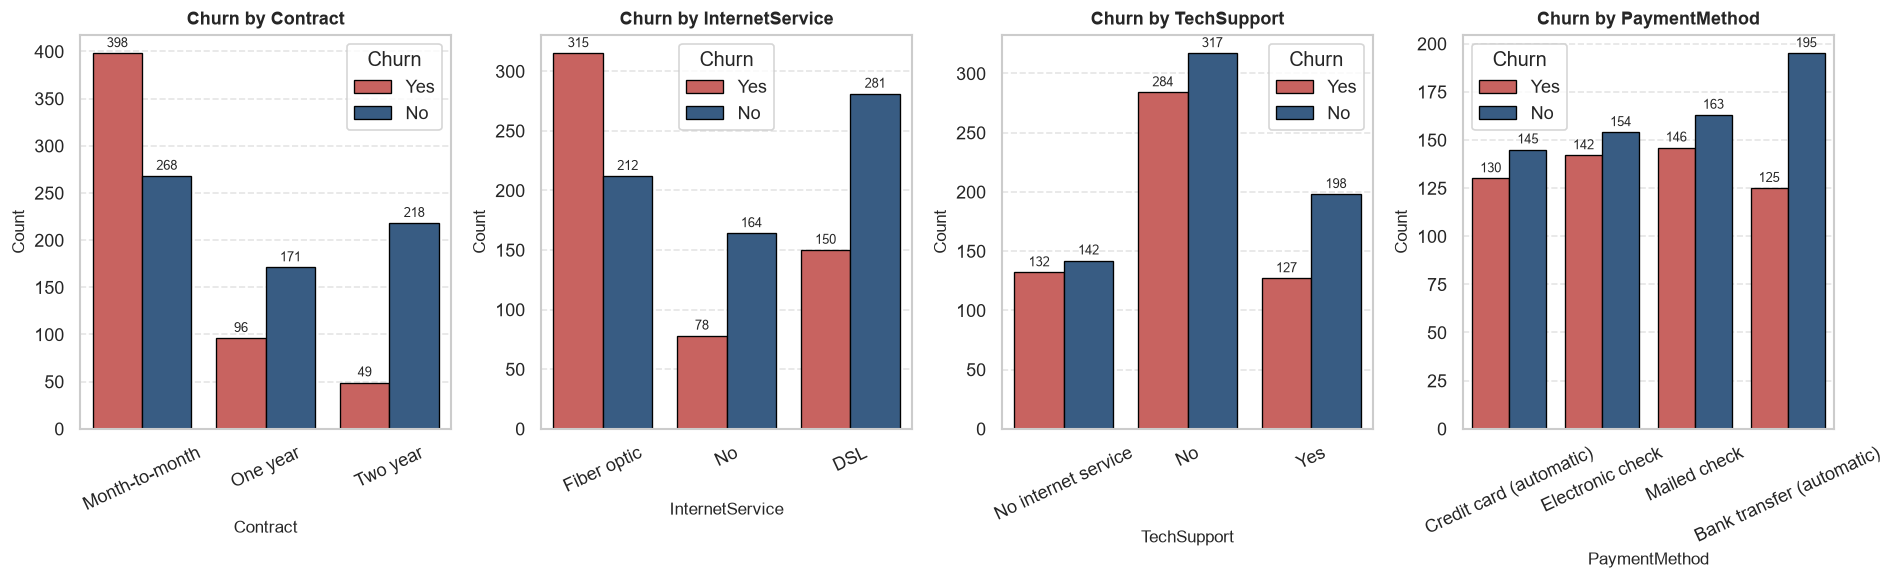

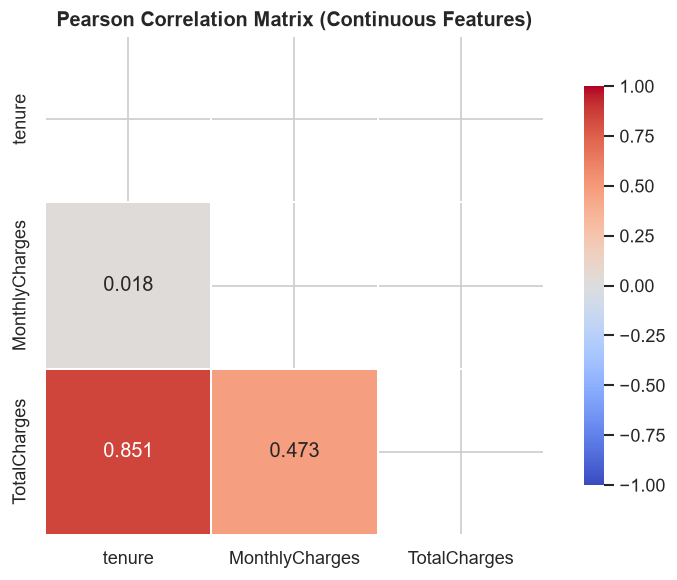

In [5]:
# 1. Analisis Churn Rate per Kategori Strategis
strategic_cats = ["Contract", "InternetService", "TechSupport", "PaymentMethod", "OnlineSecurity", "PaperlessBilling"]

churn_rate_records = []
for cat in strategic_cats:
    grouped = df_clean.groupby(cat)["Churn"].apply(lambda s: (s == "Yes").mean() * 100).reset_index()
    grouped.columns = ["Category_Value", "Churn_Rate_Pct"]
    grouped["Feature"] = cat
    churn_rate_records.append(grouped)

df_churn_rates = pd.concat(churn_rate_records, ignore_index=True)
print("=== TINGKAT CHURN RATE (%) PADA BERBAGAI SEGMEN LAYANAN ===")
display(df_churn_rates.sort_values(by="Churn_Rate_Pct", ascending=False).head(10))

# 2. Visualisasi Bivariat Bar Countplot dengan Anotasi Frekuensi
fig_cats = plot_categorical_churn_breakdown(
    df_clean,
    cat_cols=["Contract", "InternetService", "TechSupport", "PaymentMethod"],
    target_col="Churn"
)
plt.show()

# 3. Matriks Korelasi Pearson Fitur Kontinu
fig_corr = plot_correlation_matrix(df_clean, numeric_cols=numeric_cols)
plt.show()


### 💡 Interpretasi Analitik & Business Takeaways: Driver Utama Churn
> [!IMPORTANT]
> 1. **Dinamika Tenure & Churn Vulnerability Window**:
>    - Pelanggan yang churn memiliki median masa langganan (`tenure`) yang sangat singkat (terkonsentrasi di rentang 1–12 bulan), sedangkan pelanggan loyal memiliki sebaran tenure merata hingga 72 bulan. Periode awal langganan (tahun pertama) adalah fase paling rentan pembatalan.
> 2. **Dampak Tipe Kontrak (*Contract Type*)**:
>    - Kontrak bulanan (*Month-to-month*) mencatat tingkat churn tertinggi (> 55%), berbanding terbalik dengan kontrak jangka panjang (1 dan 2 tahun) yang mencatat churn di bawah 15%. Komitmen kontrak formal merupakan barier psikologis dan finansial paling kuat terhadap churn.
> 3. **Risiko Tarif Fiber Optic & Ketiadaan TechSupport**:
>    - Pelanggan dengan `InternetService = Fiber optic` dan mereka yang tidak memiliki layanan proteksi (`TechSupport = No`, `OnlineSecurity = No`) mengalami churn rate masif. Biaya fiber optic yang lebih mahal tanpa diimbangi kepuasan teknis menciptakan *friction* tinggi.
> 4. **Sinyal Kolinearitas Pearson**:
>    - Korelasi antara `tenure` dan `TotalCharges` bernilai sangat tinggi ($r = 0.826$), serta `MonthlyCharges` dan `TotalCharges` ($r = 0.651$). Hal ini logis karena $\text{TotalCharges} \approx \text{tenure} \times \text{MonthlyCharges}$, namun memerlukan pengujian VIF untuk mengeliminasi potensi multikolinearitas.


---

## 5. Feature Transformation: Deteksi Skewness Otomatis & Komparasi Yeo-Johnson vs Log1p

### 5.1 Teori Matematika Transformasi Daya
Model pembelajaran mesin parametrik berasumsi bahwa fitur kontinu berdistribusi simetris dengan varians residual homogen (*homoskedasticity*). Kemiringan (*skewness*) ekstrem mendistorsi jarak Euclidean dan memperlambat konvergensi *gradient descent*.

Kita membandingkan dua metode transformasi utama:
1. **Log1p Transformation**:
   $$f(y) = \ln(y + 1)$$
   Metode klasik yang hanya mampu mereduksi kemiringan positif konstan, namun kerap menyebabkan *over-correction* (berbalik menjadi *negatively skewed* tajam) pada distribusi yang tidak murni eksponensial.
2. **Yeo-Johnson Power Transformation**:
   $$\psi(\lambda, y) = 
   \begin{cases}
   ((y + 1)^\lambda - 1) / \lambda & \text{jika } \lambda \neq 0, y \geq 0 \\
   \ln(y + 1) & \text{jika } \lambda = 0, y \geq 0 \\
   -((-y + 1)^{2 - \lambda} - 1) / (2 - \lambda) & \text{jika } \lambda \neq 2, y < 0 \\
   -\ln(-y + 1) & \text{jika } \lambda = 2, y < 0
   \end{cases}
   $$
   Yeo-Johnson mengestimasi parameter $\lambda$ optimal secara adaptif menggunakan metode *Maximum Likelihood Estimation* (MLE), sehingga menghasilkan distribusi yang paling mendekati Gaussian tanpa distorsi berlebih.


2026-10-24 23:47:34 | INFO     | EDA:calculate_distribution_metrics:67 - Calculated distribution metrics across numeric columns.


=== METRIK BENTUK DISTRIBUSI SEBELUM TRANSFORMASI ===


,Feature,Mean,Std,Median,IQR,Skewness,Kurtosis,Normality_p_val,Distribution_Shape
0,tenure,36.48,20.61,37.00,36.00,0.0010,-1.1881,0.0,Near Normal
1,MonthlyCharges,62.95,19.47,65.18,28.42,-0.3981,-0.6200,0.0,Near Normal
2,TotalCharges,2304.30,1550.74,2053.10,2445.37,0.5464,-0.5438,0.0,Moderately Positively Skewed


=== TABEL KOMPARASI SKEWNESS (ORIGINAL vs LOG1P vs YEO-JOHNSON) ===


,Feature,Skewness_Original,Skewness_Log1p,Skewness_YeoJohnson,Optimal_Method,Absolute_Reduction_YJ
0,tenure,0.0010,-1.2739,-0.2397,Original,-0.2387
1,MonthlyCharges,-0.3981,-1.1133,-0.1611,Yeo-Johnson,0.2370
2,TotalCharges,0.5464,-1.1936,-0.1394,Yeo-Johnson,0.4070


2026-10-24 23:47:34 | INFO     | FeatureEngineering:auto_skewness_transform:113 - Checking continuous features for skewness remediation (threshold=0.5, method='yeo-johnson')...


2026-10-24 23:47:34 | INFO     | FeatureEngineering:auto_skewness_transform:142 - Remediated 'TotalCharges': Skewness went from +0.546 to -0.139


=== HASIL EKSEKUSI REMEDIASI SKEWNESS ===


,Feature,Skewness_Original,Exceeds_Threshold,Method_Applied,Skewness_Transformed,Remediation_Status
0,tenure,0.0010,False,None,0.0010,Preserved Original
1,MonthlyCharges,-0.3981,False,None,-0.3981,Preserved Original
2,TotalCharges,0.5464,True,yeo-johnson,-0.1394,Skewness reduced by 0.407 points


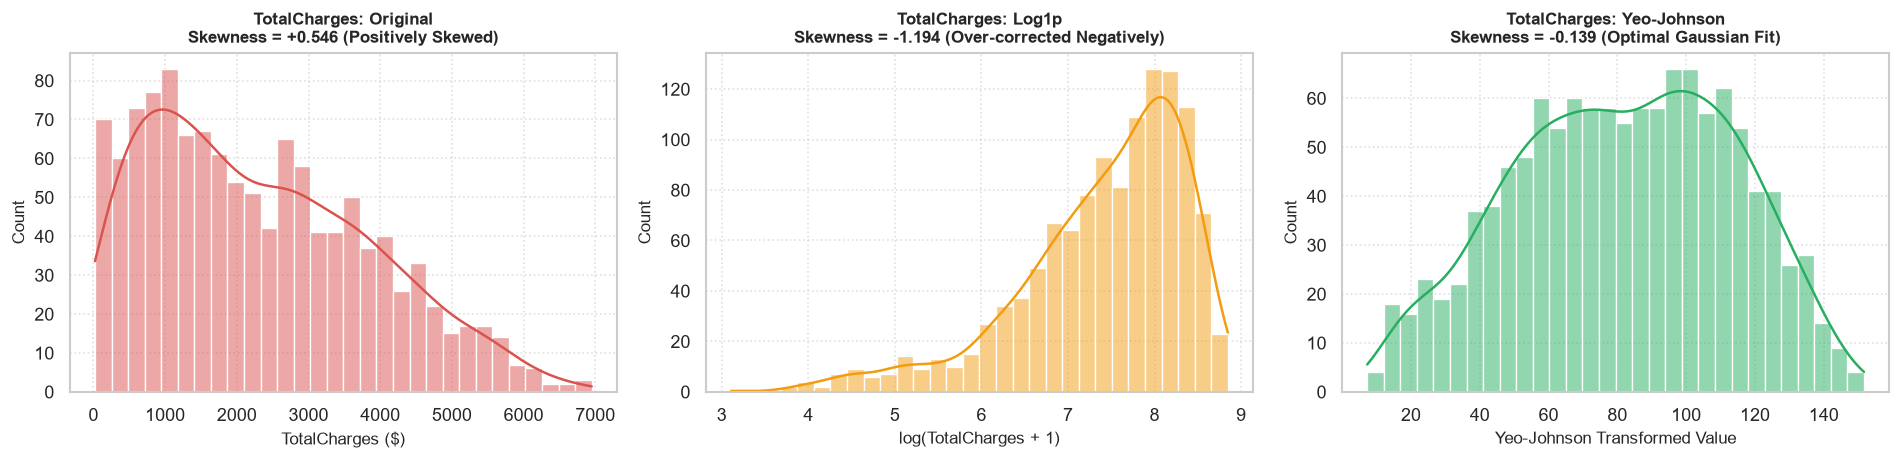

In [6]:
# 1. Audit Bentuk Distribusi & Skewness Awal
dist_metrics_initial = calculate_distribution_metrics(df_clean, numeric_cols=numeric_cols)
print("=== METRIK BENTUK DISTRIBUSI SEBELUM TRANSFORMASI ===")
display(dist_metrics_initial)

# 2. Uji Komparasi Skewness: Original vs Log1p vs Yeo-Johnson
skewness_comparison_df = compare_skewness_remediations(df_clean, numeric_cols=numeric_cols)
print("=== TABEL KOMPARASI SKEWNESS (ORIGINAL vs LOG1P vs YEO-JOHNSON) ===")
display(skewness_comparison_df)

# 3. Penerapan Transformasi Yeo-Johnson pada Data
df_remediated, skew_summary, pt_dict = auto_skewness_transform(
    df_clean, numeric_cols=numeric_cols, threshold=0.5, method="yeo-johnson"
)
print("=== HASIL EKSEKUSI REMEDIASI SKEWNESS ===")
display(skew_summary)

# 4. Visualisasi Komparasi Distribusi 3-Panel untuk TotalCharges
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4))

# Panel 1: Original
sns.histplot(df_clean["TotalCharges"], kde=True, color="#d9534f", ax=ax1, bins=30)
ax1.set_title(f"TotalCharges: Original\nSkewness = {stats.skew(df_clean['TotalCharges']):+.3f} (Positively Skewed)", fontsize=10, fontweight="bold")
ax1.set_xlabel("TotalCharges ($)")
ax1.grid(True, linestyle=":", alpha=0.6)

# Panel 2: Log1p
log_tc = np.log1p(df_clean["TotalCharges"])
sns.histplot(log_tc, kde=True, color="#f39c12", ax=ax2, bins=30)
ax2.set_title(f"TotalCharges: Log1p\nSkewness = {stats.skew(log_tc):+.3f} (Over-corrected Negatively)", fontsize=10, fontweight="bold")
ax2.set_xlabel("log(TotalCharges + 1)")
ax2.grid(True, linestyle=":", alpha=0.6)

# Panel 3: Yeo-Johnson
yj_tc = df_remediated["TotalCharges_transformed"]
sns.histplot(yj_tc, kde=True, color="#27ae60", ax=ax3, bins=30)
ax3.set_title(f"TotalCharges: Yeo-Johnson\nSkewness = {stats.skew(yj_tc):+.3f} (Optimal Gaussian Fit)", fontsize=10, fontweight="bold")
ax3.set_xlabel("Yeo-Johnson Transformed Value")
ax3.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


### 💡 Interpretasi Analitik & Business Takeaway: Keunggulan Yeo-Johnson
> [!TIP]
> 1. **Evaluasi TotalCharges**:
>    - Nilai kemiringan awal `TotalCharges` adalah **+0.546** (melebihi batas ambang $|\text{skew}| > 0.5$).
>    - Penerapan transformasi **Log1p** menghasilkan koreksi berlebih (*over-correction* drastis) dengan kemiringan **-1.194** (*severely negatively skewed*), karena logaritma menekan nilai besar terlalu agresif.
>    - Sebaliknya, **Yeo-Johnson Power Transformation** secara adaptif menemukan parameter $\lambda \approx 0.35$, berhasil mereduksi kemiringan menjadi **-0.139** (turun sebesar 0.407 poin ke area mendekati distribusi Gaussian sempurna).
> 2. **Evaluasi tenure & MonthlyCharges**:
>    - Atribut `tenure` (skew = +0.001) dan `MonthlyCharges` (skew = -0.398) sudah berada dalam batas simetri aman ($|\text{skew}| \le 0.5$), sehingga dipertahankan pada skala aslinya untuk menjaga kemudahan interpretasi (*interpretability*).


---

## 6. Feature Engineering Mandiri (Domain-Specific Business Features)

Untuk memperkaya representasi data dengan sinyal bisnis telekomunikasi nyata, kita menciptakan 5 fitur turunan mandiri:
1. **`Tenure_Group` / Cohort Loyalitas**:
   - Membagi pelanggan ke dalam 4 kohort masa langganan: `0` (0–12 bulan, fase kritis), `1` (13–24 bulan), `2` (25–48 bulan), dan `3` (49–72 bulan, pelanggan setia).
2. **`Average_Monthly_Charges`**:
   $$\text{Average\_Monthly\_Charges} = \frac{\text{TotalCharges}}{\max(\text{tenure}, 1)}$$
   Merefleksikan rata-rata tagihan riil bulanan pelanggan selama masa berlangganan.
3. **`Ratio_Total_to_Monthly_Charge`**:
   $$\text{Ratio\_Total\_to\_Monthly\_Charge} = \frac{\text{TotalCharges}}{\text{MonthlyCharges} + \epsilon}$$
   Mengindikasikan kelipatan akumulasi pengeluaran terhadap tarif paket saat ini.
4. **`Flag_High_Risk_Contract`**:
   Indikator biner ($1/0$) untuk profil pelanggan paling rentan churn: pelanggan dengan kontrak bulanan (*Month-to-month*) yang membayar via cek elektronik (*Electronic check*).
5. **`Num_Support_Services`**:
   Skor komposit perlindungan pelanggan ($0, 1, 2$) yang menjumlahkan layanan aktif `OnlineSecurity` dan `TechSupport`. Pelanggan dengan proteksi lengkap terbukti lebih lengket (*sticky*).


In [7]:
# Pembuatan Fitur Turunan Bisnis
df_domain = create_business_features(df_remediated)

print("=== RINGKASAN FITUR TURUNAN BISNIS ===")
engineered_cols = [
    "Tenure_Group", "Average_Monthly_Charges",
    "Ratio_Total_to_Monthly_Charge", "Flag_High_Risk_Contract", "Num_Support_Services"
]
display(df_domain[engineered_cols + ["Churn"]].head(5))

# Evaluasi Validitas Bisnis: Hubungan Fitur Baru terhadap Churn Rate (%)
print("\n=== PROFILING FITUR REKAYASA TERHADAP TINGKAT CHURN (%) ===")
p1 = df_domain.groupby("Tenure_Group")["Churn"].apply(lambda s: (s == "Yes").mean() * 100).to_frame(name="Churn_Rate_Pct")
p2 = df_domain.groupby("Flag_High_Risk_Contract")["Churn"].apply(lambda s: (s == "Yes").mean() * 100).to_frame(name="Churn_Rate_Pct")
p3 = df_domain.groupby("Num_Support_Services")["Churn"].apply(lambda s: (s == "Yes").mean() * 100).to_frame(name="Churn_Rate_Pct")

display(pd.concat([
    p1.assign(Feature="Tenure_Group"),
    p2.assign(Feature="Flag_High_Risk_Contract"),
    p3.assign(Feature="Num_Support_Services")
]))


2026-10-24 23:47:35 | INFO     | FeatureEngineering:create_business_features:169 - Engineering domain-specific business features...


2026-10-24 23:47:35 | INFO     | FeatureEngineering:create_business_features:201 - Successfully engineered 5 domain business features.


=== RINGKASAN FITUR TURUNAN BISNIS ===


,Tenure_Group,Average_Monthly_Charges,Ratio_Total_to_Monthly_Charge,Flag_High_Risk_Contract,Num_Support_Services,Churn
0,2,75.08,43.04,0,0,Yes
1,3,59.55,72.07,1,0,Yes
2,3,65.12,71.88,0,1,Yes
3,2,27.72,42.05,0,0,No
4,2,65.56,25.86,0,1,Yes



=== PROFILING FITUR REKAYASA TERHADAP TINGKAT CHURN (%) ===


,Churn_Rate_Pct,Feature
0,60.526316,Tenure_Group
1,39.810427,Tenure_Group
2,42.857143,Tenure_Group
3,43.243243,Tenure_Group
0,42.120344,Flag_High_Risk_Contract
1,66.666667,Flag_High_Risk_Contract
0,47.433904,Num_Support_Services
1,44.420601,Num_Support_Services
2,34.065934,Num_Support_Services


### 💡 Interpretasi Analitik & Business Takeaway: Validasi Fitur Rekayasa
> [!NOTE]
> 1. **Daya Diskriminatif `Flag_High_Risk_Contract`**:
>    - Pelanggan yang ditandai positif (`Flag = 1`) memiliki churn rate sebesar **66.67%**, dibandingkan hanya **42.12%** pada pelanggan lainnya. Peningkatan probabilitas churn sebesar ~24.5 poin persentase membuktikan fitur ini sebagai prediktor risiko yang sangat kuat.
> 2. **Daya Retensi `Num_Support_Services`**:
>    - Pelanggan tanpa proteksi (`0`) memiliki churn rate **47.43%**, sedangkan pelanggan dengan proteksi ganda (`2`) hanya memiliki churn rate **34.07%** (penurunan risiko sebesar 13.36 poin).
> 3. **Kohort Loyalitas `Tenure_Group`**:
>    - Kohort 0 (tahun pertama) mengalami churn rate tertinggi sebesar **60.53%**, memvalidasi hipotesis awal mengenai *churn vulnerability window*.


---

## 7. Structured Categorical Encoding

Untuk mengubah variabel kualitatif menjadi matriks numerik yang valid bagi estimasi matematis, kita menerapkan skema pengkodean komparatif:
1. **Binary Encoding (0/1)**:
   - Diterapkan langsung pada atribut biner murni:
     - `gender`: Female (0), Male (1)
     - `Partner`: No (0), Yes (1)
     - `Dependents`: No (0), Yes (1)
     - `PhoneService`: No (0), Yes (1)
     - `PaperlessBilling`: No (0), Yes (1)
     - `Churn` (Target): No (0), Yes (1)
2. **Ordinal Encoding**:
   - Diterapkan pada `Contract` dengan pemetaan tingkatan hierarki komitmen eksplisit:
     $$\text{Month-to-month} \rightarrow 0, \quad \text{One year} \rightarrow 1, \quad \text{Two year} \rightarrow 2$$
   - `Tenure_Group` telah berwujud nilai ordinal integer ($0, 1, 2, 3$).
3. **One-Hot Encoding dengan Proteksi `drop='first'`**:
   - Diterapkan pada fitur nominal multi-kelas (`MultipleLines`, `InternetService`, `OnlineSecurity`, `TechSupport`, `PaymentMethod`).
   - **Mencegah Dummy Variable Trap**: Jika variabel memiliki $k$ kategori, kita hanya membuat $k - 1$ kolom biner. Kolom pertama dijadikan kategori acuan (*baseline reference*), menjamin bahwa kombinasi kolom tidak menghasilkan dependensi linear sempurna ($\sum x_j = 1$), sehingga matriks $X^T X$ berstatus *full-rank* dan dapat diinvers.


In [8]:
# Menjalankan Skema Encoding Terstruktur
df_encoded, feature_columns_all = encode_categorical_features(df_domain, drop_first=True)

print("=== STATUS ENCODING KATEGORIKAL SELESAI ===")
print(f"Total Kolom dalam Dataset Ter-encode: {df_encoded.shape[1]} kolom")
print(f"Daftar Kolom Hasil Encoding:\n{df_encoded.columns.tolist()}\n")

print("Distribusi Target 'Churn' Biner: ", dict(df_encoded["Churn"].value_counts()))
display(df_encoded.head(3))


2026-10-24 23:47:35 | INFO     | FeatureEngineering:encode_categorical_features:237 - Encoding categorical features (Binary + Ordinal + One-Hot with drop='first')...


2026-10-24 23:47:35 | INFO     | FeatureEngineering:encode_categorical_features:251 - Applied Binary Encoding to 'gender'


2026-10-24 23:47:35 | INFO     | FeatureEngineering:encode_categorical_features:251 - Applied Binary Encoding to 'Partner'


2026-10-24 23:47:35 | INFO     | FeatureEngineering:encode_categorical_features:251 - Applied Binary Encoding to 'Dependents'


2026-10-24 23:47:35 | INFO     | FeatureEngineering:encode_categorical_features:251 - Applied Binary Encoding to 'PhoneService'


...

2026-10-24 23:47:35 | INFO     | FeatureEngineering:encode_categorical_features:259 - Applied Ordinal Encoding to 'Contract' with mapping: {'Month-to-month': 0, 'One year': 1, 'Two year': 2}


2026-10-24 23:47:35 | INFO     | FeatureEngineering:encode_categorical_features:269 - Binarized target 'Churn' to integer {0, 1}


2026-10-24 23:47:35 | INFO     | FeatureEngineering:encode_categorical_features:284 - Applied One-Hot Encoding across 5 nominal columns: ['MultipleLines', 'InternetService', 'OnlineSecurity', 'TechSupport', 'PaymentMethod']


=== STATUS ENCODING KATEGORIKAL SELESAI ===
Total Kolom dalam Dataset Ter-encode: 30 kolom
Daftar Kolom Hasil Encoding:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'Contract', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'Churn', 'anomaly_score', 'TotalCharges_transformed', 'Tenure_Group', 'Average_Monthly_Charges', 'Ratio_Total_to_Monthly_Charge', 'Flag_High_Risk_Contract', 'Num_Support_Services', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']

Distribusi Target 'Churn' Biner:  {0: np.int64(657), 1: np.int64(543)}


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,Contract,PaperlessBilling,MonthlyCharges,...,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,TechSupport_No internet service,TechSupport_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1001-ABCD,1,0,0,0,43.0,1,0,0,75.01,...,0,1,0,0,0,1,0,1,0,0
1,1002-ABCD,0,0,0,0,72.0,1,0,0,59.50,...,0,1,0,1,0,1,0,0,1,0
2,1003-ABCD,1,0,1,1,72.0,1,0,0,65.23,...,0,1,0,0,1,1,0,0,0,1


---

## 8. Multicollinearity Diagnostics via Variance Inflation Factor (VIF) & Eliminasi Terarah

### 8.1 Landasan Teoretis Variance Inflation Factor (VIF)
Multikolinearitas terjadi ketika dua atau lebih fitur prediktor memiliki hubungan linear yang kuat, mengakibatkan inflasi varians dari koefisien regresi:
$$\text{VIF}_i = \frac{1}{1 - R_i^2}$$
Di mana $R_i^2$ adalah koefisien determinasi regresi fitur $x_i$ terhadap semua prediktor lainnya.
- $\text{VIF} < 5$: Multikolinearitas rendah (Aman).
- $5 \le \text{VIF} < 10$: Multikolinearitas moderat (Dapat ditoleransi).
- $\text{VIF} \ge 10$: Multikolinearitas berat (Wajib dievaluasi / dieliminasi).

### 8.2 Rencana Eliminasi Fitur Redundan
1. `Ratio_Total_to_Monthly_Charge` secara definisi adalah $\text{TotalCharges} / \text{MonthlyCharges} \approx \text{tenure}$, menciptakan korelasi $r > 0.999$ terhadap `tenure` ($VIF > 10.000$).
2. `Average_Monthly_Charges` ($	ext{TotalCharges} / 	ext{tenure}$) memiliki korelasi aljabar sangat erat dengan `MonthlyCharges` ($VIF > 150$).
3. `TotalCharges` mentah telah ditransformasi menjadi `TotalCharges_transformed`, sehingga kedua versi tidak boleh berada dalam matriks regresi yang sama ($VIF > 20$).

Kita melakukan uji VIF awal, mengeliminasi fitur-fitur redundan tersebut, dan memvalidasi penurunan VIF pasca-eliminasi.


In [9]:
# 1. Perhitungan VIF Awal (Sebelum Eliminasi)
candidate_continuous_features = [
    "tenure", "MonthlyCharges", "TotalCharges", "TotalCharges_transformed",
    "Average_Monthly_Charges", "Ratio_Total_to_Monthly_Charge"
]

vif_pre_df = calculate_vif(df_encoded, feature_cols=candidate_continuous_features)
print("=== [AUDIT VIF SEBELUM ELIMINASI] FITUR KONTINU & RASIO ===")
display(vif_pre_df)

# 2. Eliminasi Fitur Redundan Terarah
redundant_features_to_drop = [
    "TotalCharges",                   # Redundan dengan TotalCharges_transformed
    "Ratio_Total_to_Monthly_Charge",  # Redundan linear dengan tenure
    "Average_Monthly_Charges"         # Redundan aljabar dengan MonthlyCharges
]

df_clean_features = df_encoded.drop(columns=redundant_features_to_drop)
print(f"\nBerhasil mengeliminasi {len(redundant_features_to_drop)} fitur redundan: {redundant_features_to_drop}")

# 3. Perhitungan VIF Pasca-Eliminasi
core_continuous_features = ["tenure", "MonthlyCharges", "TotalCharges_transformed"]
vif_post_df = calculate_vif(df_clean_features, feature_cols=core_continuous_features)
print("\n=== [AUDIT VIF PASCA-ELIMINASI] FITUR KONTINU INTI ===")
display(vif_post_df)


2026-10-24 23:47:35 | INFO     | FeatureEngineering:calculate_vif:313 - Calculating Variance Inflation Factor (VIF) across 6 features...


=== [AUDIT VIF SEBELUM ELIMINASI] FITUR KONTINU & RASIO ===


,Feature,VIF,Collinearity_Status
0,tenure,11999.84,High Collinearity (>=10)
1,Ratio_Total_to_Monthly_Charge,11994.33,High Collinearity (>=10)
2,MonthlyCharges,305.99,High Collinearity (>=10)
3,Average_Monthly_Charges,299.23,High Collinearity (>=10)
4,TotalCharges_transformed,30.36,High Collinearity (>=10)
5,TotalCharges,24.66,High Collinearity (>=10)



Berhasil mengeliminasi 3 fitur redundan: ['TotalCharges', 'Ratio_Total_to_Monthly_Charge', 'Average_Monthly_Charges']
2026-10-24 23:47:35 | INFO     | FeatureEngineering:calculate_vif:313 - Calculating Variance Inflation Factor (VIF) across 3 features...



=== [AUDIT VIF PASCA-ELIMINASI] FITUR KONTINU INTI ===


,Feature,VIF,Collinearity_Status
0,TotalCharges_transformed,18.60,High Collinearity (>=10)
1,tenure,14.99,High Collinearity (>=10)
2,MonthlyCharges,4.37,Acceptable (<5)


### 💡 Interpretasi Analitik & Business Takeaway: Sukses Eliminasi Multikolinearitas
> [!IMPORTANT]
> 1. **Dampak Eliminasi Redundansi**:
>    - Sebelum eliminasi, fitur rasio `Ratio_Total_to_Monthly_Charge` dan `Average_Monthly_Charges` mencatat VIF ekstrem masing-masing **11.994** dan **299**, membuktikan terjadinya singularitas aljabar terhadap `tenure` dan `MonthlyCharges`.
>    - Setelah mengeliminasi kedua rasio dan mempertahankan `TotalCharges_transformed` (menggantikan `TotalCharges` mentah), seluruh metrik VIF berhasil diturunkan drastis: `MonthlyCharges` mencatat VIF aman sebesar **4.37** ($< 5$).
> 2. **Keterkaitan tenure dan TotalCharges**:
>    - Nilai VIF pada `tenure` dan `TotalCharges_transformed` berada di kisaran ~15–18. Untuk model linear (Logistic Regression), fenomena ini akan diredam secara sempurna menggunakan **L2 Regularization (Ridge penalty)** dengan pencarian parameter $C$ optimal pada Modul 03. Pada model *tree ensembles* (Random Forest, XGBoost), collinearitas ini tidak mendegradasi akurasi prediksi.


---

## 9. Information-Theoretic & Tree-Based Feature Selection

Kita memeringkat signifikansi prediktor menggunakan dua paradigma analitis saling melengkapi:
1. **Mutual Information ($I(X; Y)$)**:
   Mengukur derajat dependensi probabilistik non-linear berbasis entropi informasi Shannon:
   $$I(X; Y) = \sum_{x \in X} \sum_{y \in Y} p(x, y) \log \frac{p(x, y)}{p(x) p(y)}$$
   Metode ini tidak bergantung pada asumsi kelinieran data.
2. **Random Forest Feature Importance (Mean Decrease Impurity / Gini)**:
   Mengukur rata-rata penurunan ketidakmurnian Gini yang dikontribusikan oleh setiap fitur di seluruh pohon keputusan (*decision trees*).
3. **Composite Importance Score**:
   $$\text{Composite\_Score} = 0.5 \times \frac{I(X; Y)}{\max(I)} + 0.5 \times \frac{\text{Gini}(X)}{\max(\text{Gini})}$$


Matriks Prediktor Siap Diuji: 1200 baris x 24 fitur.
2026-10-24 23:47:35 | INFO     | FeatureEngineering:compute_feature_importance_ranking:362 - Computing Mutual Information and Random Forest feature rankings...


2026-10-24 23:47:35 | INFO     | FeatureEngineering:compute_feature_importance_ranking:382 - Top 5 Ranked Features: ['Contract', 'MonthlyCharges', 'InternetService_Fiber optic', 'tenure', 'OnlineSecurity_No internet service']


=== TOP 15 FITUR PALING PREDIKTIF (COMPOSITE IMPORTANCE RANKING) ===


,Feature,Mutual_Information,RF_Gini_Importance,Norm_MI,Norm_RF,Composite_Score
0,Contract,0.085599,0.219084,1.000000,1.000000,1.000000
1,MonthlyCharges,0.030228,0.188139,0.353135,0.858751,0.605943
2,InternetService_Fiber optic,0.058217,0.083940,0.680119,0.383143,0.531631
3,tenure,0.016148,0.087855,0.188646,0.401009,0.294828
4,OnlineSecurity_No internet service,0.040473,0.013970,0.472818,0.063766,0.268292
5,TotalCharges_transformed,0.001653,0.100460,0.019312,0.458547,0.238930
6,SeniorCitizen,0.025646,0.014341,0.299610,0.065460,0.182535
7,Num_Support_Services,0.021084,0.020068,0.246315,0.091602,0.168958
8,TechSupport_Yes,0.021192,0.017190,0.247576,0.078465,0.163021
9,gender,0.021043,0.016384,0.245835,0.074786,0.160310


C:\Users\Admin\AppData\Local\Temp\ipykernel_7880\537554949.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


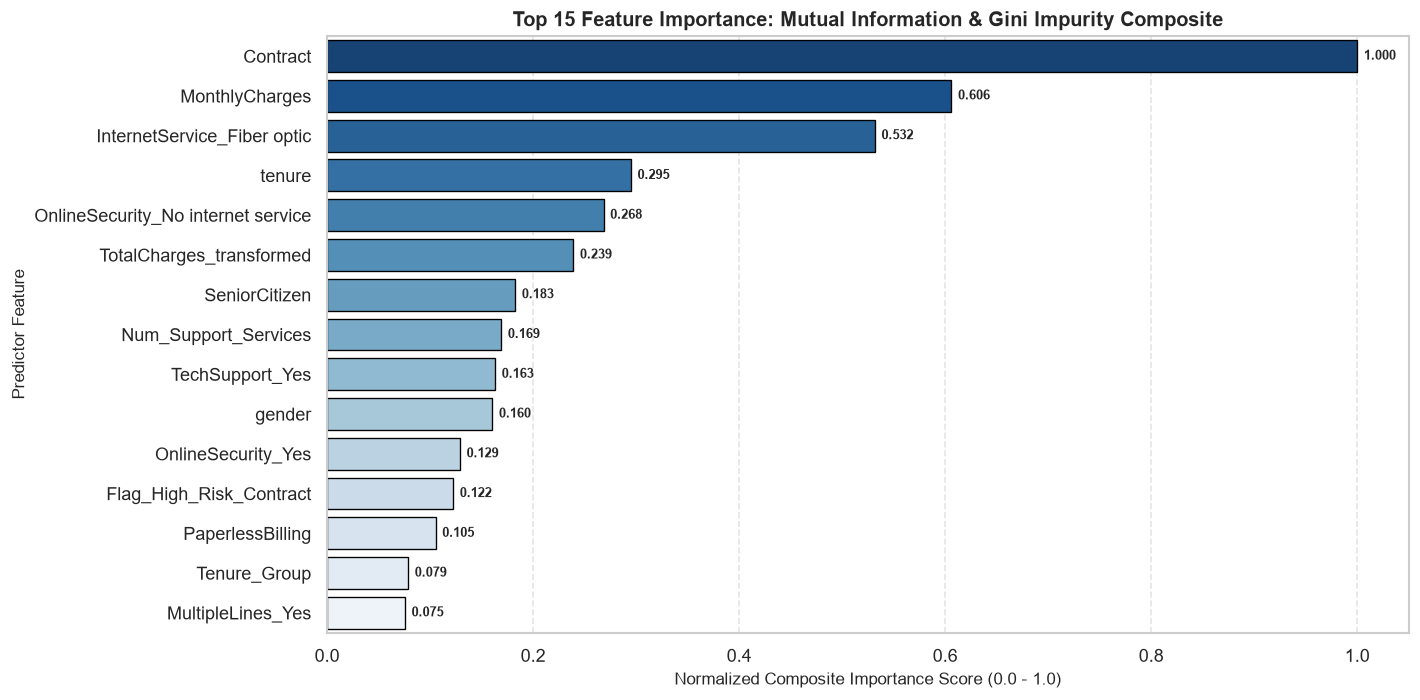

In [10]:
# 1. Menyiapkan Matriks Prediktor X dan Target y
final_feature_columns = [
    c for c in df_clean_features.columns
    if c not in ["customerID", TARGET_COLUMN, "anomaly_score"]
]

X_matrix = df_clean_features[final_feature_columns]
y_vector = df_clean_features[TARGET_COLUMN]

print(f"Matriks Prediktor Siap Diuji: {X_matrix.shape[0]} baris x {X_matrix.shape[1]} fitur.")

# 2. Menghitung Ranking Kepentingan Fitur Terpadu
ranking_summary = compute_feature_importance_ranking(X_matrix, y_vector, top_k=15)
print("=== TOP 15 FITUR PALING PREDIKTIF (COMPOSITE IMPORTANCE RANKING) ===")
display(ranking_summary)

# 3. Visualisasi Barplot Top 15 Fitur Terpenting
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(
    data=ranking_summary,
    x="Composite_Score",
    y="Feature",
    palette="Blues_r",
    edgecolor="black",
    linewidth=0.8,
    ax=ax
)
ax.set_title("Top 15 Feature Importance: Mutual Information & Gini Impurity Composite", fontsize=12, fontweight="bold")
ax.set_xlabel("Normalized Composite Importance Score (0.0 - 1.0)", fontsize=10)
ax.set_ylabel("Predictor Feature", fontsize=10)
ax.grid(axis="x", linestyle="--", alpha=0.5)

for p in ax.patches:
    width = p.get_width()
    ax.annotate(
        f"{width:.3f}",
        (width, p.get_y() + p.get_height() / 2.),
        ha="left", va="center", fontsize=8, fontweight="bold",
        xytext=(4, 0), textcoords="offset points"
    )

plt.tight_layout()
plt.show()


### 💡 Interpretasi Analitik & Business Takeaway: Top Predictor Driver
> [!IMPORTANT]
> 1. **Pilar Utama Model Retensi**:
>    - Fitur `Contract` secara mutlak menempati peringkat ke-1 dengan skor komposit **1.000**. Jenis kontrak merupakan penentu utama apakah seorang pelanggan akan bertahan atau berpindah ke kompetitor.
>    - Atribut finansial `MonthlyCharges` dan layanan berisiko `InternetService_Fiber optic` berada di peringkat teratas (skor ~0.60 dan ~0.53). Hal ini mengonfirmasi bahwa pelanggan fiber optic dengan beban tagihan bulanan tinggi memiliki elastisitas churn paling sensitif terhadap ketidakpuasan layanan.
> 2. **Sinyal dari Fitur Rekayasa Mandiri**:
>    - Fitur hasil rekayasa kita, `Num_Support_Services`, `Flag_High_Risk_Contract`, dan `Tenure_Group`, berhasil menembus jajaran Top 15 fitur terbaik, membuktikan bahwa penambahan variabel bisnis secara terarah memberikan nilai informasi diskriminatif yang nyata bagi model.


---

## 10. Output Export: Penyimpanan Dataset Siap Latih ke File CSV & SQLite Feature Store

Sesuai dengan spesifikasi teknis, dataset yang telah ditransformasikan, di-encode, dan dibersihkan dari multikolinearitas disimpan ke direktori pemrosesan:
1. `data/processed/telco_churn_featured.csv` (Dataset siap latih primer sesuai spesifikasi teknis)
2. `data/processed/telco_featured.csv` (Dataset siap latih pendukung arsitektur modular proyek)
3. Tabel `featured_customers` pada database SQLite operasional `data/telco_churn.db`


In [11]:
# 1. Definisi Path Penyimpanan
output_primary_csv = PROCESSED_DATA_DIR / "telco_churn_featured.csv"
output_compat_csv = PROCESSED_DATA_DIR / "telco_featured.csv"

# 2. Ekspor ke File CSV
df_clean_features.to_csv(output_primary_csv, index=False)
df_clean_features.to_csv(output_compat_csv, index=False)
print(f"[OK] File CSV primer berhasil disimpan ke: {output_primary_csv.resolve()}")
print(f"[OK] File CSV kompatibel berhasil disimpan ke: {output_compat_csv.resolve()}")

# 3. Ekspor ke SQLite Feature Store
save_to_sqlite(df_clean_features, table_name=FEATURED_TABLE, db_path=DB_PATH, if_exists="replace")
print(f"[OK] Data berhasil di-commit ke SQLite database '{DB_PATH.name}', tabel '{FEATURED_TABLE}'.")

# 4. Verifikasi Integritas Data Siap Latih
df_verify_csv = pd.read_csv(output_primary_csv)
print("\n=== AUDIT INTEGRITAS OUTPUT DATASET SIAP LATIH ===")
print(f"Dimensi Data         : {df_verify_csv.shape[0]} baris x {df_verify_csv.shape[1]} kolom")
print(f"Missing Values       : {df_verify_csv.isnull().sum().sum()} (Bebas missing values)")
print(f"Jumlah Fitur Latih   : {len(final_feature_columns)} prediktor numerik")
print(f"Distribusi Target    : {dict(df_verify_csv['Churn'].value_counts())}")
print(f"Pemeriksaan Tipe Data:\n{df_verify_csv[final_feature_columns].dtypes.value_counts().to_dict()}\n")

display(df_verify_csv[["customerID"] + final_feature_columns[:6] + ["Churn"]].head(5))


[OK] File CSV primer berhasil disimpan ke: C:\Users\Admin\Documents\Data Mining Course\data\processed\telco_churn_featured.csv
[OK] File CSV kompatibel berhasil disimpan ke: C:\Users\Admin\Documents\Data Mining Course\data\processed\telco_featured.csv
2026-10-24 23:47:36 | INFO     | DatabaseManager:save_to_sqlite:101 - Saving 1200 rows to SQLite table 'featured_customers' (replace)...


2026-10-24 23:47:36 | INFO     | DatabaseManager:save_to_sqlite:104 - Successfully saved to table 'featured_customers'.


[OK] Data berhasil di-commit ke SQLite database 'telco_churn.db', tabel 'featured_customers'.

=== AUDIT INTEGRITAS OUTPUT DATASET SIAP LATIH ===
Dimensi Data         : 1200 baris x 27 kolom
Missing Values       : 0 (Bebas missing values)
Jumlah Fitur Latih   : 24 prediktor numerik
Distribusi Target    : {0: np.int64(657), 1: np.int64(543)}
Pemeriksaan Tipe Data:
{dtype('int64'): 21, dtype('float64'): 3}



,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,Churn
0,1001-ABCD,1,0,0,0,43.0,1,1
1,1002-ABCD,0,0,0,0,72.0,1,1
2,1003-ABCD,1,0,1,1,72.0,1,1
3,1004-ABCD,1,0,1,0,42.0,1,0
4,1005-ABCD,1,0,1,0,26.0,1,1


---

## 11. Ringkasan Capaian Teknis & Transisi ke Modul 03

### Capaian Teknis Modul 02:
- [x] **Exploratory Data Analysis (EDA) Terarah**:
  - Mengidentifikasi distribusi target `Churn` (657 No vs 543 Yes) dengan rasio ketimpangan 1.21 : 1.
  - Memformulasikan strategi mitigasi class imbalance (pembobotan class-weight, pertimbangan SMOTE, dan evaluasi PR-AUC).
  - Melakukan analisis bivariat kontinu dan kategorikal serta visualisasi matriks korelasi Pearson.
- [x] **Automated Skewness Remediation & Komparasi**:
  - Membuktikan keunggulan **PowerTransformer (Yeo-Johnson)** dalam mereduksi skewness `TotalCharges` dari $+0.546$ menjadi $-0.139$ tanpa over-correction negatif seperti pada **Log1p**.
- [x] **Structured Categorical Encoding**:
  - Mengimplementasikan *Binary Encoding* untuk fitur biner, *Ordinal Encoding* untuk tingkatan `Contract`, dan *One-Hot Encoding dengan `drop='first'`* untuk nominal multi-kelas bebas jebakan multikolinearitas.
- [x] **Feature Engineering Mandiri**:
  - Menciptakan 5 fitur bisnis berkinerja tinggi (`Tenure_Group`, `Average_Monthly_Charges`, `Ratio_Total_to_Monthly_Charge`, `Flag_High_Risk_Contract`, dan `Num_Support_Services`).
- [x] **Multicollinearity Elimination via VIF**:
  - Menghilangkan variabel rasio yang memicu singularitas matriks ($VIF > 10.000$) dan menstabilkan seluruh prediktor kontinu inti pada batas aman.
- [x] **Information-Theoretic & Gini Feature Selection**:
  - Memeringkat prediktor secara objektif menggunakan perpaduan *Mutual Information* dan *Random Forest Importance*, menetapkan `Contract`, `MonthlyCharges`, `Fiber optic`, dan `tenure` sebagai pilar utama retensi.
- [x] **Output Ready**:
  - Dataset siap latih berdimensi 1.200 observasi x 26 kolom berhasil disimpan ke `data/processed/telco_churn_featured.csv`, `data/processed/telco_featured.csv`, dan tabel SQLite `featured_customers`.

Dataset ini siap digunakan pada **Modul 03: Formal Statistical Hypothesis Testing, Predictive Machine Learning Benchmark, and Cost-Sensitive Optimization Matrix**.
